<a href="https://colab.research.google.com/github/siva09777/IR-Task2-SMS-Spam-Classification/blob/main/IR_Task2_SMS_Spam_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pandas numpy scikit-learn matplotlib seaborn nltk

In [ ]:
import pandas as pd

# Load SMS Spam Collection Dataset
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

df = pd.read_csv(url, sep='\t', header=None,
                 names=['label', 'message'])

# Display dataset information
print("Total Messages:", len(df))

print("\nClass Distribution:")
print(df['label'].value_counts())

print("\nFirst 10 Messages:")
display(df.head(10))

Total Messages: 5572

Class Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

First 10 Messages:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


In [ ]:
import nltk
import re

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download('stopwords')

stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()

    # Remove numbers and special characters
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Tokenization
    words = text.split()

    # Remove stopwords and apply stemming
    words = [
        stemmer.stem(word)
        for word in words
        if word not in stop_words
    ]

    return ' '.join(words)

# Apply preprocessing
df['cleaned_message'] = df['message'].apply(preprocess_text)

# Display results
print("TEXT PREPROCESSING RESULTS")
display(df[['message', 'cleaned_message']].head(10))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


TEXT PREPROCESSING RESULTS


,message,cleaned_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi n great world...
1,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri wkli comp win fa cup final tkt st m...
3,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darl week word back like fun still...
6,Even my brother is not like to speak with me. ...,even brother like speak treat like aid patent
7,As per your request 'Melle Melle (Oru Minnamin...,per request mell mell oru minnaminungint nurun...
8,WINNER!! As a valued network customer you have...,winner valu network custom select receivea pri...
9,Had your mobile 11 months or more? U R entitle...,mobil month u r entitl updat latest colour mob...


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

# Convert labels into numbers
# ham = 0, spam = 1
df['target'] = df['label'].map({'ham': 0, 'spam': 1})

# Separate input and output
X = df['cleaned_message']
y = df['target']

# Split dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Apply TF-IDF
tfidf = TfidfVectorizer(max_features=3000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Display results
print("TF-IDF Conversion Successful!")

print("Training Documents:", X_train_tfidf.shape[0])
print("Testing Documents:", X_test_tfidf.shape[0])
print("Total TF-IDF Features:", X_train_tfidf.shape[1])

print("\nSample TF-IDF Matrix:")
display(pd.DataFrame(
    X_train_tfidf[:5].toarray(),
    columns=tfidf.get_feature_names_out()
).iloc[:, :10])

TF-IDF Conversion Successful!
Training Documents: 4457
Testing Documents: 1115
Total TF-IDF Features: 3000

Sample TF-IDF Matrix:


,aah,aathi,ab,abbey,abdomen,abeg,abel,aberdeen,abi,abil
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import pandas as pd
import time

# Define four algorithms
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': LinearSVC(random_state=42),
    'Naive Bayes': MultinomialNB()
}

results = []
predictions = {}

# Train and evaluate each model
for name, model in models.items():

    start_time = time.time()

    model.fit(X_train_tfidf, y_train)

    y_pred = model.predict(X_test_tfidf)
    predictions[name] = y_pred

    elapsed_time = time.time() - start_time

    results.append({
        'Algorithm': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0),
        'Time (seconds)': round(elapsed_time, 3)
    })

# Display comparison table
results_df = pd.DataFrame(results)

print("MACHINE LEARNING MODEL COMPARISON")
display(results_df.round(4))

MACHINE LEARNING MODEL COMPARISON


,Algorithm,Accuracy,Precision,Recall,F1 Score,Time (seconds)
0,Decision Tree,0.9668,0.9000,0.8456,0.8720,0.353
1,KNN,0.9202,1.0000,0.4027,0.5742,0.167
2,SVM,0.9821,0.9850,0.8792,0.9291,0.014
3,Naive Bayes,0.9758,0.9919,0.8255,0.9011,0.004


In [ ]:
from sklearn.metrics import confusion_matrix

for name, y_pred in predictions.items():
    print("\nAlgorithm:", name)
    print(confusion_matrix(y_test, y_pred))

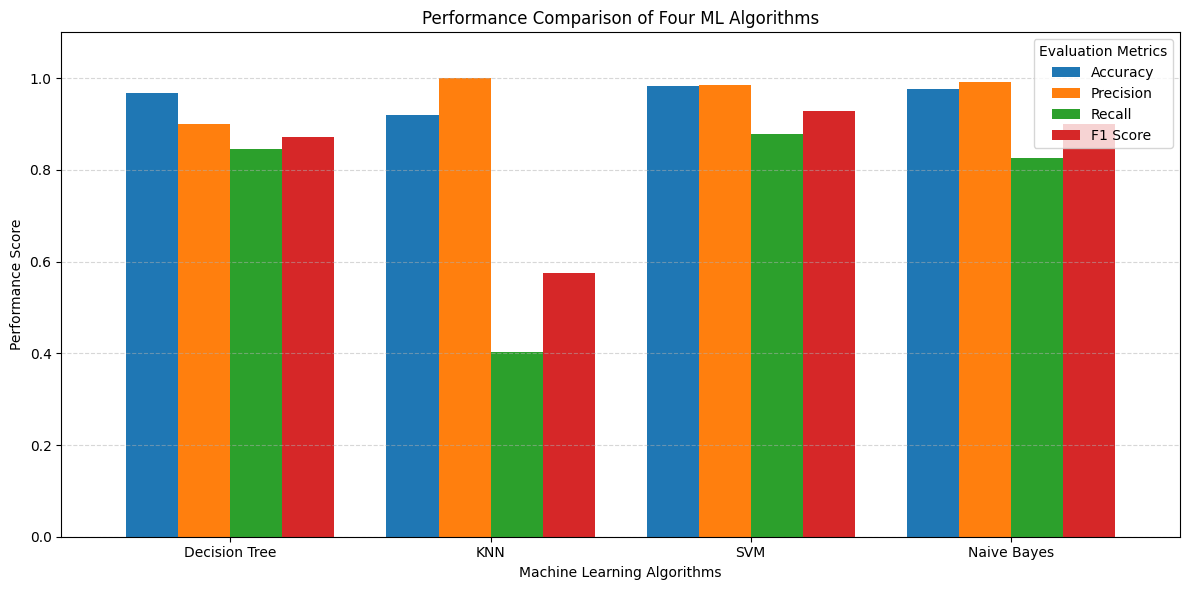

Comparison graph generated successfully!


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Select evaluation metrics
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

# Create comparison graph
ax = results_df.set_index('Algorithm')[metrics].plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title('Performance Comparison of Four ML Algorithms')
plt.xlabel('Machine Learning Algorithms')
plt.ylabel('Performance Score')
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.legend(title='Evaluation Metrics')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

# Save graph
plt.savefig('model_comparison.png', dpi=300)

plt.show()

print("Comparison graph generated successfully!")

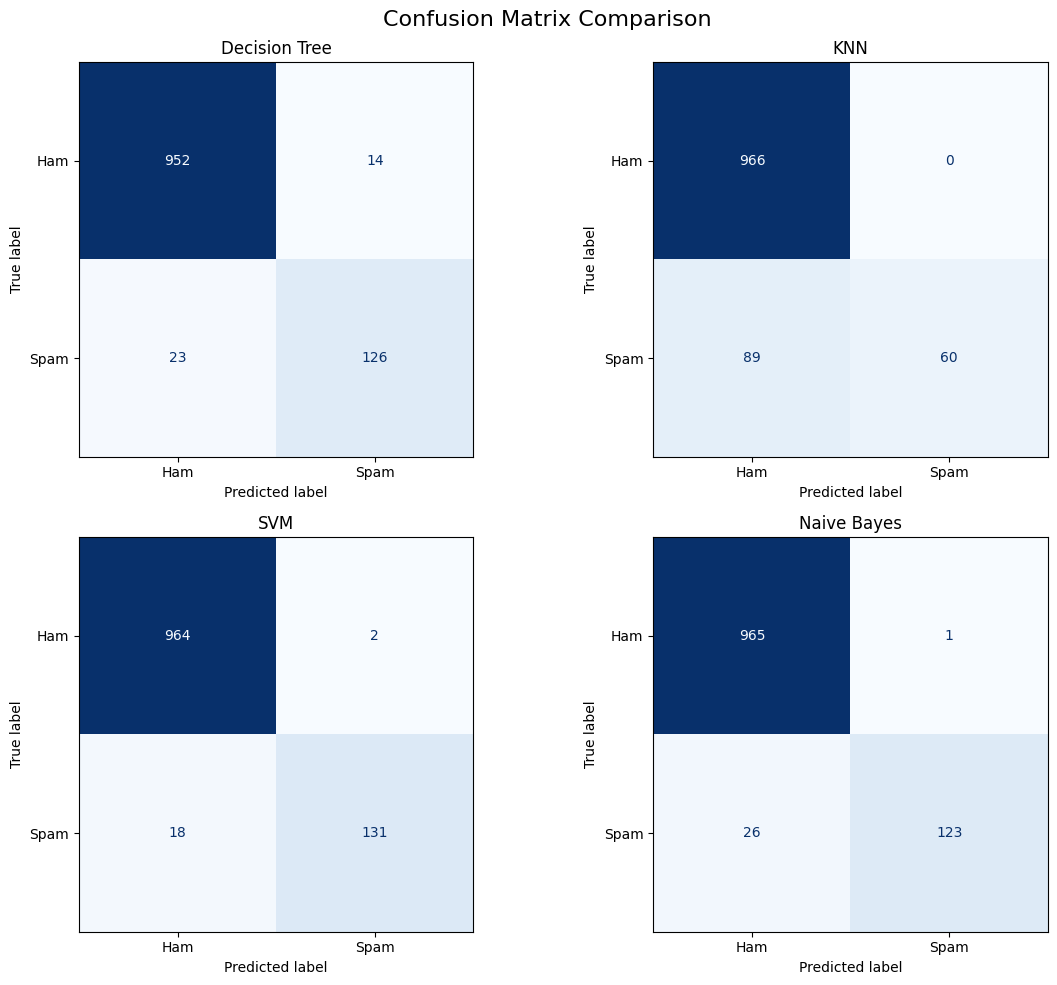

All four confusion matrices generated successfully!


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate confusion matrices for all four models

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, y_pred) in zip(axes.flatten(), predictions.items()):

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Ham', 'Spam']
    )

    disp.plot(ax=ax, cmap='Blues', colorbar=False)

    ax.set_title(name)

plt.suptitle('Confusion Matrix Comparison', fontsize=16)

plt.tight_layout()

# Save the image
plt.savefig('confusion_matrices.png', dpi=300)

plt.show()

print("All four confusion matrices generated successfully!")

WHAT-IF EXPERIMENT: CHANGING K VALUE


,K Value,Accuracy,F1 Score
0,1,0.956054,0.804781
1,3,0.931839,0.660714
2,5,0.920179,0.574163
3,7,0.909417,0.487310
4,9,0.904933,0.459184


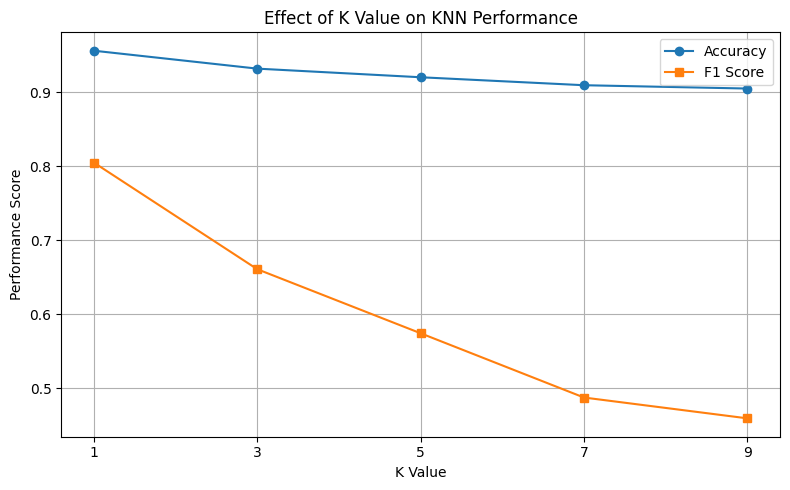

What-If Experiment Completed Successfully!


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt

# Test different K values
k_values = [1, 3, 5, 7, 9]

what_if_results = []

for k in k_values:

    knn = KNeighborsClassifier(n_neighbors=k)

    knn.fit(X_train_tfidf, y_train)

    y_pred = knn.predict(X_test_tfidf)

    what_if_results.append({
        'K Value': k,
        'Accuracy': accuracy_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred, zero_division=0)
    })

# Display results
what_if_df = pd.DataFrame(what_if_results)

print("WHAT-IF EXPERIMENT: CHANGING K VALUE")
display(what_if_df)

# Generate graph
plt.figure(figsize=(8, 5))

plt.plot(
    what_if_df['K Value'],
    what_if_df['Accuracy'],
    marker='o',
    label='Accuracy'
)

plt.plot(
    what_if_df['K Value'],
    what_if_df['F1 Score'],
    marker='s',
    label='F1 Score'
)

plt.title('Effect of K Value on KNN Performance')
plt.xlabel('K Value')
plt.ylabel('Performance Score')
plt.xticks(k_values)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig('what_if_experiment.png', dpi=300)

plt.show()

print("What-If Experiment Completed Successfully!")

In [ ]:
# Identify best model based on F1 Score
best_model = results_df.loc[
    results_df['F1 Score'].idxmax()
]

print("FINAL MODEL EVALUATION")
print("----------------------------")

display(results_df.round(4))

print("\nBEST PERFORMING ALGORITHM")
print("Algorithm:", best_model['Algorithm'])
print("Accuracy:", round(best_model['Accuracy'] * 100, 2), "%")
print("Precision:", round(best_model['Precision'] * 100, 2), "%")
print("Recall:", round(best_model['Recall'] * 100, 2), "%")
print("F1 Score:", round(best_model['F1 Score'] * 100, 2), "%")

# Save results
results_df.to_csv('model_results.csv', index=False)
what_if_df.to_csv('what_if_results.csv', index=False)

print("\nResults saved successfully!")

FINAL MODEL EVALUATION
----------------------------


,Algorithm,Accuracy,Precision,Recall,F1 Score,Time (seconds)
0,Decision Tree,0.9668,0.9000,0.8456,0.8720,0.353
1,KNN,0.9202,1.0000,0.4027,0.5742,0.167
2,SVM,0.9821,0.9850,0.8792,0.9291,0.014
3,Naive Bayes,0.9758,0.9919,0.8255,0.9011,0.004



BEST PERFORMING ALGORITHM
Algorithm: SVM
Accuracy: 98.21 %
Precision: 98.5 %
Recall: 87.92 %
F1 Score: 92.91 %

Results saved successfully!


In [ ]:
from google.colab import files

files.download('model_results.csv')
files.download('what_if_results.csv')
files.download('model_comparison.png')
files.download('confusion_matrices.png')
files.download('what_if_experiment.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download('model_results.csv')
files.download('what_if_results.csv')
files.download('model_comparison.png')
files.download('confusion_matrices.png')
files.download('what_if_experiment.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.metrics import confusion_matrix

for name, y_pred in predictions.items():
    print("\n", name)
    print(confusion_matrix(y_test, y_pred))


 Decision Tree
[[952  14]
 [ 23 126]]

 KNN
[[966   0]
 [ 89  60]]

 SVM
[[964   2]
 [ 18 131]]

 Naive Bayes
[[965   1]
 [ 26 123]]


In [ ]:
import shutil
from google.colab import files

shutil.make_archive(
    'IR_Task2_Results',
    'zip',
    '.',
    base_dir='.'
)

files.download('IR_Task2_Results.zip')

In [18]:
import zipfile
from google.colab import files

file_names = [
    'model_results.csv',
    'what_if_results.csv',
    'model_comparison.png',
    'confusion_matrices.png',
    'what_if_experiment.png'
]

with zipfile.ZipFile('IR_Task2_Results.zip', 'w') as zipf:
    for file in file_names:
        zipf.write(file)

print("ZIP file created successfully!")

files.download('IR_Task2_Results.zip')

ZIP file created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
from google.colab import files
files.download('model_results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>